# Dance Classification - Data Preprocessing

### Imports

In [1]:
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

### Reading in the Data

The following 2 code cells read in the data. There are loops because each sample needs to be read in individually. It also creates a DataFrame and adds the loaded in data into the DataFrame with columns for timestamps, keypoints, and labels.

In [2]:
# let's select house and ballet jazz and load in the data

df = pd.DataFrame(columns=['timestamps', 'keypoints', 'label'])
#  example adding a row ---> df.loc[len(df)] = [timestamp_value, keypoints_value, label_value]

file_paths = [
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch01.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch02.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch03.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch04.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch05.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch06.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch07.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch08.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch09.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch10.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO1_ch01.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO1_ch02.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO1_ch03.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO1_ch04.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO1_ch05.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO1_ch06.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO1_ch07.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO1_ch08.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO1_ch09.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO1_ch10.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO2_ch01.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO2_ch02.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO2_ch03.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO2_ch04.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO2_ch05.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO2_ch06.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO2_ch07.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO2_ch08.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO2_ch09.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO2_ch10.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO3_ch01.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO3_ch02.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO3_ch03.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO3_ch04.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO3_ch05.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO3_ch06.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO3_ch07.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO3_ch08.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO3_ch09.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO3_ch10.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO0_ch01.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO0_ch02.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO0_ch03.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO0_ch04.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO0_ch05.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO0_ch06.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO0_ch07.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO0_ch08.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO0_ch09.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO0_ch10.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO1_ch01.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO1_ch02.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO1_ch03.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO1_ch04.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO1_ch05.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO1_ch06.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO1_ch07.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO1_ch08.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO1_ch09.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO1_ch10.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO4_ch01.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO4_ch02.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO4_ch03.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO4_ch04.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO4_ch05.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO4_ch06.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO4_ch07.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO4_ch08.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO4_ch09.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO4_ch10.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO5_ch01.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO5_ch02.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO5_ch03.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO5_ch04.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO5_ch05.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO5_ch06.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO5_ch07.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO5_ch08.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO5_ch09.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d20_mHO5_ch10.pkl'
]

# Loop over the file paths
for file_path in file_paths:
    with open(file_path, 'rb') as file:
        data = pickle.load(file)
    keypoints = data['keypoints2d'][0]
    timestamps = data['timestamps']
    # Add a row to the DataFrame
    df.loc[len(df)] = [timestamps, keypoints, "house"]


In [3]:
file_paths = [
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch01.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch02.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch03.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch04.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch05.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch06.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch07.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch08.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch09.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch10.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB1_ch01.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB1_ch02.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB1_ch03.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB1_ch04.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB1_ch05.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB1_ch06.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB1_ch07.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB1_ch08.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB1_ch09.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB1_ch10.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB2_ch01.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB2_ch02.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB2_ch03.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB2_ch04.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB2_ch05.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB2_ch06.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB2_ch07.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB2_ch08.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB2_ch09.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB2_ch10.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB3_ch01.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB3_ch02.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB3_ch03.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB3_ch04.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB3_ch05.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB3_ch06.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB3_ch07.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB3_ch08.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB3_ch09.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB3_ch10.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB0_ch01.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB0_ch02.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB0_ch03.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB0_ch04.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB0_ch05.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB0_ch06.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB0_ch07.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB0_ch08.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB0_ch09.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB0_ch10.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB1_ch01.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB1_ch02.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB1_ch03.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB1_ch04.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB1_ch05.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB1_ch06.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB1_ch07.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB1_ch08.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB1_ch09.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB1_ch10.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB4_ch01.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB4_ch02.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB4_ch03.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB4_ch04.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB4_ch05.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB4_ch06.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB4_ch07.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB4_ch08.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB4_ch09.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB4_ch10.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB5_ch01.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB5_ch02.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB5_ch03.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB5_ch04.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB5_ch05.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB5_ch06.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB5_ch07.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB5_ch08.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB5_ch09.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d08_mJB5_ch10.pkl'
]

# Loop over the file paths
for file_path in file_paths:
    with open(file_path, 'rb') as file:
        data = pickle.load(file)
    keypoints = data['keypoints2d'][0]
    timestamps = data['timestamps']
    # Add a row to the DataFrame
    df.loc[len(df)] = [timestamps, keypoints, "ballet_jazz"]

df['keypoints'][0]

array([[[9.6200000e+02, 5.0700000e+02, 9.9114478e-01],
        [9.7000000e+02, 4.9900000e+02, 9.9733233e-01],
        [9.5300000e+02, 4.9900000e+02, 9.9922502e-01],
        ...,
        [9.2500000e+02, 7.7200000e+02, 8.4655535e-01],
        [9.7000000e+02, 8.5500000e+02, 8.6714959e-01],
        [8.9100000e+02, 8.4900000e+02, 8.3388120e-01]],

       [[9.6300000e+02, 5.0900000e+02, 9.8698676e-01],
        [9.6900000e+02, 5.0100000e+02, 9.9385107e-01],
        [9.5300000e+02, 5.0100000e+02, 1.0021371e+00],
        ...,
        [9.2200000e+02, 7.7300000e+02, 8.6814195e-01],
        [9.7100000e+02, 8.5400000e+02, 8.7219805e-01],
        [8.9000000e+02, 8.5000000e+02, 8.7317604e-01]],

       [[9.6100000e+02, 5.0900000e+02, 9.9206805e-01],
        [9.6900000e+02, 5.0300000e+02, 9.9651408e-01],
        [9.5100000e+02, 5.0300000e+02, 9.9844795e-01],
        ...,
        [9.2000000e+02, 7.7200000e+02, 8.5773551e-01],
        [9.7100000e+02, 8.5300000e+02, 8.8125628e-01],
        [8.9000000e+02

### Building Feature Vectors

#### Velocity

The following code can be used to calculate the velocities of each of the keypoints given the keypoint arrays.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm


def calculate_velocity(keypoints):
    """
    Calculate the velocity between frames for keypoints data.
    
    Parameters:
        keypoints (numpy.ndarray): Array of shape (N, 17, 3), where N is the number
                                   of frames, 17 is the number of keypoints, and the
                                   last dimension represents (x, y, confidence level).
    
    Returns:
        numpy.ndarray: Array of shape (N-1, 17) containing the velocity magnitude
                       for each keypoint between consecutive frames.
    """
    # Extract the (x, y) coordinates, ignoring the confidence level
    positions = keypoints[:, :, :2]
    
    # Calculate the differences between consecutive frames
    delta_positions = np.diff(positions, axis=0)
    
    # Calculate the velocity magnitude for each keypoint
    velocity = np.linalg.norm(delta_positions, axis=2)
    
    return velocity


# Example usage
keypoints = df['keypoints'][0]


Now, thay can be calculated for the entire data frame, and then I will add them each to their own column in the data frame so they can be used in training the model.

In [5]:
# Now to calculate for the entire data frame
body_parts = ["nose","left_eye","right_eye","left_ear","right_ear","left_shoulder","right_shoulder","left_elbow",
             "right_elbow","left_wrist","right_wrist","left_hip","right_hip","left_knee","right_knee","left_ankle",
             "right_ankle"]

vel_list = []
for _, row in df.iterrows():
    keypoints = row["keypoints"]
    velocities = calculate_velocity(keypoints)
    vel_list.append(velocities)
    
df['velocities'] = vel_list

# Adding average velocities for each keypoint

df['average_velocities'] = df['velocities'].apply(lambda vel_list: np.mean(vel_list, axis=0))

# splitting averages to individual columns
num_keypoints = len(body_parts)
for i in range(num_keypoints):
    df[f"{i}_vel"] = df['average_velocities'].apply(lambda x: x[i])

# updated DataFrame
df.head()

,timestamps,keypoints,label,velocities,average_velocities,0_vel,1_vel,2_vel,3_vel,4_vel,...,7_vel,8_vel,9_vel,10_vel,11_vel,12_vel,13_vel,14_vel,15_vel,16_vel
0,"[0, 16667, 33333, 50000, 66667, 83333, 100000,...","[[[962.0, 507.0, 0.9911448], [970.0, 499.0, 0....",house,"[[2.236068, 2.236068, 2.0, 4.0, 0.0, 2.0, 2.23...","[2.119693, 2.0828161, 2.0683346, 2.0028377, 2....",2.119693,2.082816,2.068335,2.002838,2.012040,...,3.429454,3.480467,5.426296,5.984886,2.399910,2.423934,2.450052,2.844239,2.589095,2.896642
1,"[0, 16667, 33333, 50000, 66667, 83333, 100000,...","[[[969.0, 518.0, 0.990416], [977.0, 510.0, 0.9...",house,"[[3.1622777, 3.1622777, 3.0, 5.0990195, 4.4721...","[2.9731882, 2.9230354, 2.8939242, 2.8577065, 2...",2.973188,2.923035,2.893924,2.857707,2.867610,...,4.014082,3.743870,4.533906,4.683378,2.948297,2.972696,2.997117,3.050395,3.493483,3.481331
2,"[0, 16667, 33333, 50000, 66667, 83333, 100000,...","[[[928.0, 518.0, 0.99365795], [937.0, 512.0, 1...",house,"[[4.472136, 5.0, 4.0, 4.472136, 4.0, 5.3851647...","[3.1669786, 3.0975099, 3.0257978, 3.0514991, 2...",3.166979,3.097510,3.025798,3.051499,2.933426,...,3.997649,3.992900,4.963068,4.542530,3.139170,3.146769,4.025468,3.877844,4.870522,4.629562
3,"[0, 16667, 33333, 50000, 66667, 83333, 100000,...","[[[989.0, 521.0, 0.99302423], [998.0, 514.0, 0...",house,"[[3.0, 3.1622777, 3.1622777, 3.1622777, 3.1622...","[2.7222846, 2.670291, 2.6603901, 2.7458787, 2....",2.722285,2.670291,2.660390,2.745879,2.707404,...,4.501568,4.695504,5.661072,5.400831,3.489862,3.482738,3.401538,3.563521,4.529806,4.462624
4,"[0, 16667, 33333, 50000, 66667, 83333, 100000,...","[[[973.0, 508.0, 0.9983996], [983.0, 503.0, 0....",house,"[[0.0, 1.4142135, 1.0, 0.0, 0.0, 1.4142135, 2....","[3.2355325, 3.2595994, 3.1986387, 3.2087786, 3...",3.235533,3.259599,3.198639,3.208779,3.170679,...,4.032535,4.165546,4.844517,4.244980,2.563845,2.536845,2.525510,2.549100,2.420054,2.531660


### Average Change in Distance Between Nose and Left Ankle

This could show how often the dancer lifts their leg or moves their upper body.

In [6]:
# Calculate the average difference between keypoints at index 0 and index 16 for each sample.

# Step 1: Define a function to calculate the Euclidean distance between two points.
def calculate_distance(point1, point2):
    point1_xy = np.array(point1[:2])  # Extract [x, y] for point1
    point2_xy = np.array(point2[:2])  # Extract [x, y] for point2
    return np.linalg.norm(point2_xy - point1_xy)  # Compute Euclidean distance

# Step 2: Define a function to calculate the average change in distance.
def calculate_avg_distance_change(keypoints):
    keypoint_0 = keypoints[0]
    keypoint_16 = keypoints[16]
    return calculate_distance(keypoint_0, keypoint_16)  # Compute distance between keypoints 0 and 16

# Step 3: Apply the function to the 'keypoints' column to calculate distance change for each sample.
df['avg_distance_change_keypoints_0_16'] = df['keypoints'].apply(calculate_avg_distance_change)
df.head()


,timestamps,keypoints,label,velocities,average_velocities,0_vel,1_vel,2_vel,3_vel,4_vel,...,8_vel,9_vel,10_vel,11_vel,12_vel,13_vel,14_vel,15_vel,16_vel,avg_distance_change_keypoints_0_16
0,"[0, 16667, 33333, 50000, 66667, 83333, 100000,...","[[[962.0, 507.0, 0.9911448], [970.0, 499.0, 0....",house,"[[2.236068, 2.236068, 2.0, 4.0, 0.0, 2.0, 2.23...","[2.119693, 2.0828161, 2.0683346, 2.0028377, 2....",2.119693,2.082816,2.068335,2.002838,2.012040,...,3.480467,5.426296,5.984886,2.399910,2.423934,2.450052,2.844239,2.589095,2.896642,10.535656
1,"[0, 16667, 33333, 50000, 66667, 83333, 100000,...","[[[969.0, 518.0, 0.990416], [977.0, 510.0, 0.9...",house,"[[3.1622777, 3.1622777, 3.0, 5.0990195, 4.4721...","[2.9731882, 2.9230354, 2.8939242, 2.8577065, 2...",2.973188,2.923035,2.893924,2.857707,2.867610,...,3.743870,4.533906,4.683378,2.948297,2.972696,2.997117,3.050395,3.493483,3.481331,30.248968
2,"[0, 16667, 33333, 50000, 66667, 83333, 100000,...","[[[928.0, 518.0, 0.99365795], [937.0, 512.0, 1...",house,"[[4.472136, 5.0, 4.0, 4.472136, 4.0, 5.3851647...","[3.1669786, 3.0975099, 3.0257978, 3.0514991, 2...",3.166979,3.097510,3.025798,3.051499,2.933426,...,3.992900,4.963068,4.542530,3.139170,3.146769,4.025468,3.877844,4.870522,4.629562,11.180355
3,"[0, 16667, 33333, 50000, 66667, 83333, 100000,...","[[[989.0, 521.0, 0.99302423], [998.0, 514.0, 0...",house,"[[3.0, 3.1622777, 3.1622777, 3.1622777, 3.1622...","[2.7222846, 2.670291, 2.6603901, 2.7458787, 2....",2.722285,2.670291,2.660390,2.745879,2.707404,...,4.695504,5.661072,5.400831,3.489862,3.482738,3.401538,3.563521,4.529806,4.462624,21.863213
4,"[0, 16667, 33333, 50000, 66667, 83333, 100000,...","[[[973.0, 508.0, 0.9983996], [983.0, 503.0, 0....",house,"[[0.0, 1.4142135, 1.0, 0.0, 0.0, 1.4142135, 2....","[3.2355325, 3.2595994, 3.1986387, 3.2087786, 3...",3.235533,3.259599,3.198639,3.208779,3.170679,...,4.165546,4.844517,4.244980,2.563845,2.536845,2.525510,2.549100,2.420054,2.531660,5.567776


### Correlation Matrix with the Features

This will help determine which features will be more helpful in building the model.

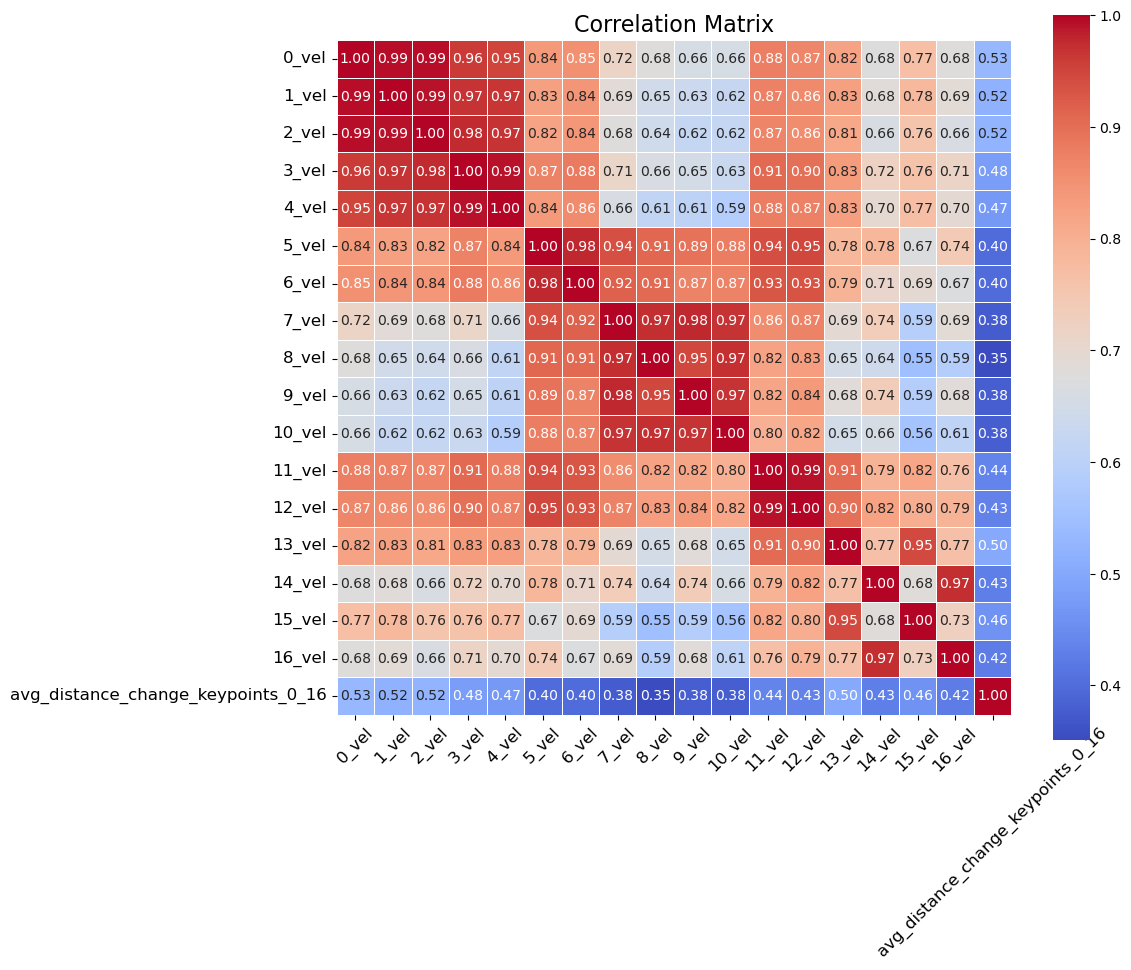

In [7]:
# First simplify data frame
df_new = df.drop(columns=["timestamps", "keypoints", "label", "velocities", "average_velocities"])

# Calculate the correlation matrix
correlation_matrix = df_new.corr()

# Plot the correlation matrix
plt.figure(figsize=(12, 10))  # Adjust the figure size to avoid overlaps
sns.heatmap(
    correlation_matrix,
    annot=True,             # Annotate with correlation values
    fmt=".2f",              # Limit annotation to 2 decimal places
    cmap="coolwarm",        # Use a visually appealing colormap
    cbar=True,              # Add a color bar
    annot_kws={"size": 10}, # Set annotation font size
    square=True,            # Make heatmap cells square
    linewidths=0.5          # Makes white separation lines around the cells
)
plt.title("Correlation Matrix", fontsize=16)  # Set title size
plt.xticks(fontsize=12, rotation=45)          # Rotate x-axis labels for better readability
plt.yticks(fontsize=12, rotation=0)           # Keep y-axis labels horizontal
plt.tight_layout()                            # Adjust layout to fit everything
plt.show()


As seen above, the highest correlations are generally seen along the diagonal, which makes sense because the keypoints nearest to each other in numerical order also tend to be those nearest each other on the body. It makes sense that the body parts near each other might have similar velocities. It is also key to note that the average distance feature (which measures the distance between the nose and the right ankle) does not have a high correlation with any of the other variables. The high correlations between keypoints such as 0, 1, and 2 might mean that these keypoints are redundant and unnecessary for the model. I will explore that as I tune the model.